In [1]:
import jax
import jax.numpy as jnp 
import WDM
import WDM_LISAresponse
import numpy as np
import matplotlib.pyplot as plt
from WDM_LISAresponse.code.utils.utils import compare_response_signals
from WDM_LISAresponse.code.lisa_response.response_sub import basis_tensors
from WDM_LISAresponse.code.lisa_response.response import one_arm_response_td, one_arm_response_freq_domain, one_arm_response_wdm, one_arm_response_wdm_dT
import time 
from lisaorbits.file import read_orbit_file
from lisaorbits import InterpolatedOrbits
from scipy.signal.windows import tukey


year_SI = 3.154e7

key = jax.random.PRNGKey(0)

In [2]:
def waveform_polarisations(time, A_plus, A_cross, f, phi_0):
    """
    This is for a sine wave signal.

    Parameters
    ----------
    time : ndarray
        time in the solar system barycenter [s]
    A_plus : float
        plus polarisation amplitude [strain]
    A_cross : float
        cross polarisation amplitude [strain]
    f : float
        GW frequency [Hz]
    phi_0 : float
        phase angle [rad]

    Returns
    -------
    h_plus : ndarray
        plus polarised signal, shaped like time.
    h_cross : ndarray
        cross polarised signal, shaped like time.
    """
    h_plus = A_plus * np.cos(2*np.pi*f*time+phi_0)
    h_cross = A_cross * np.sin(2*np.pi*f*time+phi_0)
    return h_plus, h_cross

In [3]:
theta, phi = jnp.array(1.0), jnp.array(1.0)
basis_tensors(theta, phi)

num_points = 100

key, subkey = jax.random.split(key)
theta = jax.random.uniform(key, shape=(num_points,), minval=0.0, maxval=jnp.pi)

key, subkey = jax.random.split(key)
phi = jax.random.uniform(key, shape=(num_points,), minval=0.0, maxval=2*jnp.pi)
polarisation_basis=jnp.zeros((num_points,2, 3, 3))
t_start = time.time()
for i in jnp.arange(num_points):    
    polarisation_basis = polarisation_basis.at[i,:,:,:].set(basis_tensors(theta[i], phi[i]))
    polarisation_basis.block_until_ready()
t_end = time.time()

print(f"Computed {num_points} basis tensors in {t_end - t_start} seconds")

Computed 100 basis tensors in 0.5522181987762451 seconds


In [4]:
#Inject orbital data into our system

orbit_data = read_orbit_file('esa-trailing-orbits.h5')

orbit_times = orbit_data.t0 + orbit_data.dt * np.arange(orbit_data.size)
t_start = orbit_data.t0

orbits_trailing = InterpolatedOrbits(orbit_times, 
                                     orbit_data.positions, 
                                     orbit_data.velocities)

In [5]:
#waveform signal 

theta, phi, A_plus, A_cross, f, phi_0 = np.pi/2, 0.0, 5e-22, 0.0, 3.0e-3, 0.0

t_start = orbit_data.t0+year_SI
#t_end = t_start + 0.001*year_SI
times = np.arange(t_start, t_start+5*6000, 5)

h_plus_td, h_cross_td = waveform_polarisations(times, A_plus, A_cross, f, phi_0)
alpha = 0.05
N_tukey = len(times)
print("Lenght of array is", N_tukey)

w = tukey(N_tukey, alpha=alpha)

n_start = int(np.ceil(0.5*alpha * (N_tukey - 1)))
n_end = int(np.floor((1-alpha * 0.5) * (N_tukey - 1))) + 1

w_h_plus_td = w * h_plus_td
w_h_cross_td = w * h_cross_td

Lenght of array is 6000


In [16]:
t_start_timer = time.time()
dl_sr = one_arm_response_td(times, 1, 2, orbits_trailing, theta, phi, w_h_plus_td, w_h_cross_td, num_int_points=500)
t_end_timer = time.time()
num_points = len(dl_sr)
print(f"Computed {num_points} points in {t_end_timer - t_start_timer} seconds using time domain")

t_start_timer = time.time()
dl_sr_freq = one_arm_response_freq_domain(times, 1, 2, orbits_trailing, theta, phi, w_h_plus_td, w_h_cross_td)
t_end_timer = time.time()
num_points = len(dl_sr_freq)
print(f"Computed {num_points} points in {t_end_timer - t_start_timer} seconds using frequency domain")

t_start_timer = time.time()
dl_sr_wdm, h_approx, good, tau_s = one_arm_response_wdm(times, 1, 2, orbits_trailing, theta, phi, w_h_plus_td, w_h_cross_td, Nf = 1000)
t_end_timer = time.time()
num_points = len(dl_sr_wdm)
print(f"Computed {num_points} points in {t_end_timer - t_start_timer} seconds using time-frequency domain")

t_start_timer = time.time()
dl_sr_wdm_dT, _ = one_arm_response_wdm_dT(times, 1, 2, orbits_trailing, theta, phi, w_h_plus_td, w_h_cross_td, Nf=1000, return_td = True)
t_end_timer = time.time()
num_points = len(dl_sr_wdm_dT)
print(f"Computed {num_points} points in {t_end_timer - t_start_timer} seconds using time-frequency domain with dT approx")

Computed 6000 points in 0.3095247745513916 seconds using time domain
Computed 6000 points in 49.59810996055603 seconds using frequency domain
Current length of time series: 6000
WDM_transform(Nf=1000, N=6000, q=1, d=4, A_frac=0.25, calc_m0=True)
self.Nt = 6 time cells
self.Nf = 1000 frequency cells
self.dT = 5000.0 time resolution
self.dF = 0.0001 frequency resolution
self.K = 2000 window length
Padded length of time series: 6000
How much padding was added: 0.0
tq min/max: 440.99776577949524 30437.43529033661 T: 30000.0 frac_out: 0.014666666666666666
Computed 6000 points in 16.462152004241943 seconds using time-frequency domain
Current length of time series: 6000
WDM_transform(Nf=1000, N=6000, q=1, d=4, A_frac=0.25, calc_m0=True)
self.Nt = 6 time cells
self.Nf = 1000 frequency cells
self.dT = 5000.0 time resolution
self.dF = 0.0001 frequency resolution
self.K = 2000 window length
Padded length of time series: 6000
How much padding was added: 0.0
Computed 6000 points in 6.77377414703369

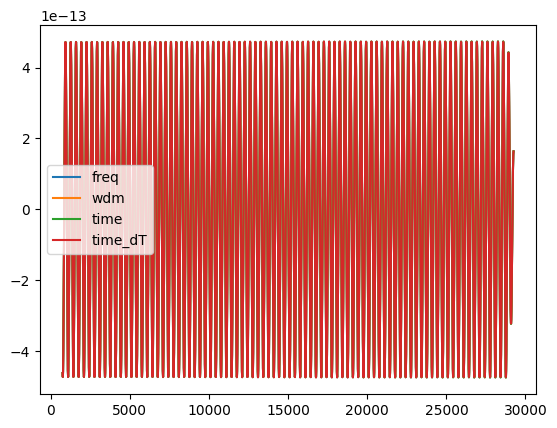

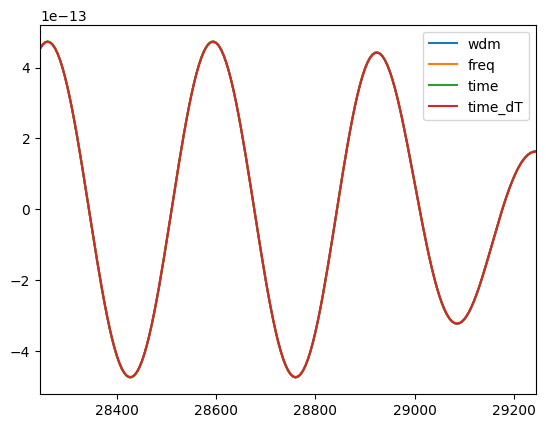

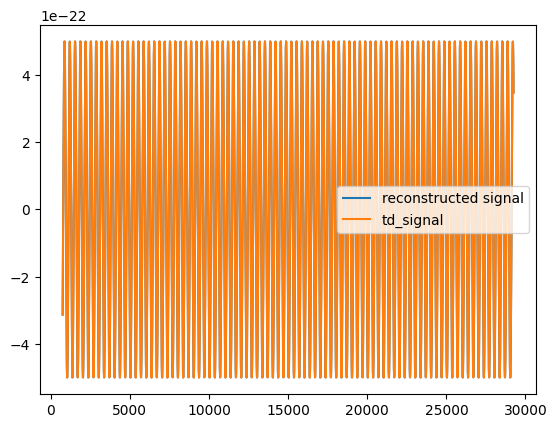

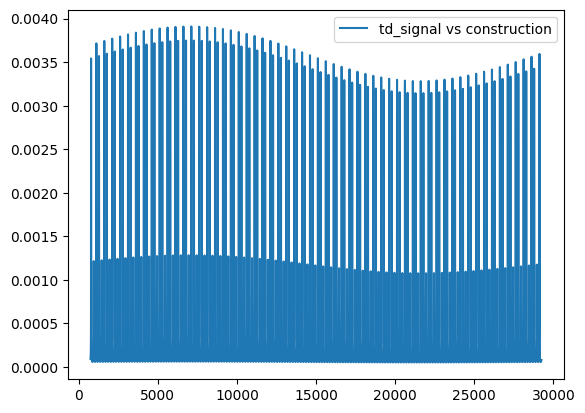

In [17]:
plotting_times = times[n_start:n_end] - times[0]

plt.plot(plotting_times, dl_sr_freq[n_start:n_end], label= "freq")
plt.plot(plotting_times, dl_sr_wdm[n_start:n_end], label="wdm")
plt.plot(plotting_times, dl_sr[n_start:n_end], label="time")
plt.plot(plotting_times, dl_sr_wdm_dT[n_start:n_end], label="time_dT")
plt.legend()
plt.show()

plt.plot(plotting_times, dl_sr_wdm[n_start:n_end], label="wdm")
plt.plot(plotting_times, dl_sr_freq[n_start:n_end], label= "freq")
plt.plot(plotting_times, dl_sr[n_start:n_end], label="time")
plt.plot(plotting_times, dl_sr_wdm_dT[n_start:n_end], label="time_dT")
plt.legend()
plt.xlim(plotting_times[-1]-1000, plotting_times[-1])
plt.show()

plt.plot(plotting_times, h_approx[n_start:n_end], label="reconstructed signal")
plt.plot(plotting_times, w_h_plus_td[n_start:n_end], label="td_signal")
plt.legend()
plt.show()

plt.plot(plotting_times, np.abs(w_h_plus_td[n_start:n_end]-h_approx[n_start:n_end]) / (np.abs(w_h_plus_td[n_start:n_end])+ 1e-30), label="td_signal vs construction")
plt.legend()
plt.show()





In [18]:
res = compare_response_signals(w_h_plus_td[n_start:n_end], h_approx[n_start:n_end])

print(res['mismatch'])
print(res['rel_L2'])


3.0706168718808158e-09
7.836668209079593e-05


TD vs FD has stats:
7.771561172376096e-16
1.3509031728595857e-07
TD vs WDM (no time approx) has stats:
3.1701536951089793e-09
7.963506922250374e-05
TD vs WDM (time approx) has stats:
3.991858171792373e-07
0.000939048790732441
WDM (no time approx) vs WDM (time approx) has stats:
3.949128691838055e-07
0.0009341180224190477


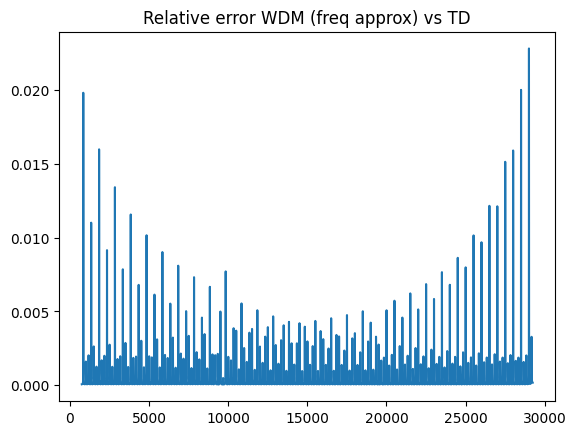

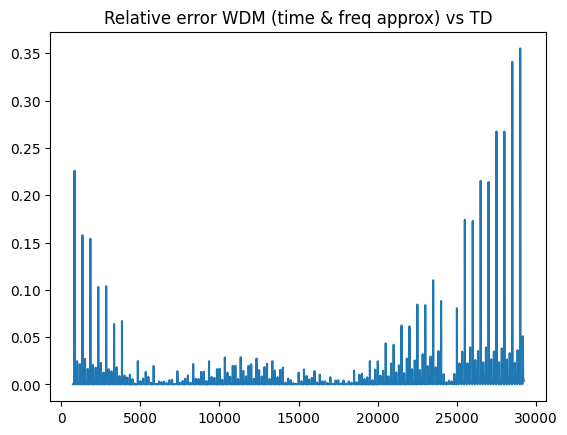

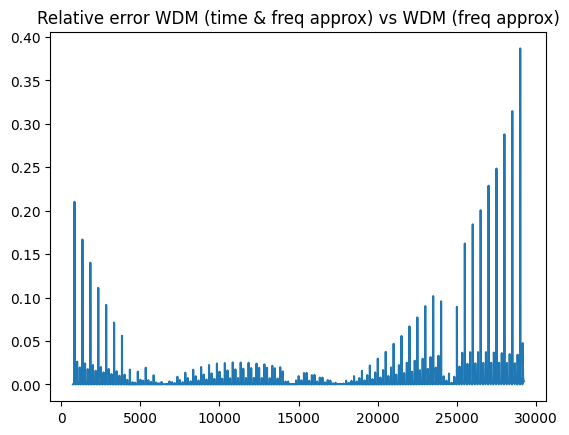

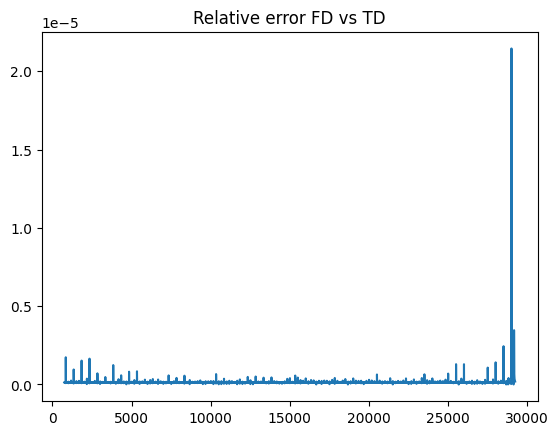

In [19]:


res1 = compare_response_signals(dl_sr[n_start:n_end], dl_sr_freq[n_start:n_end])
res2 = compare_response_signals(dl_sr[n_start:n_end], dl_sr_wdm[n_start:n_end])
res3 = compare_response_signals(dl_sr[n_start:n_end], dl_sr_wdm_dT[n_start:n_end])
res4 = compare_response_signals(dl_sr_wdm[n_start:n_end], dl_sr_wdm_dT[n_start:n_end])

print("TD vs FD has stats:")
print(res1['mismatch'])
print(res1['rel_L2'])

print("TD vs WDM (no time approx) has stats:")
print(res2['mismatch'])
print(res2['rel_L2'])

print("TD vs WDM (time approx) has stats:")
print(res3['mismatch'])
print(res3['rel_L2'])

print("WDM (no time approx) vs WDM (time approx) has stats:")
print(res4['mismatch'])
print(res4['rel_L2'])

plt.plot(plotting_times, np.abs(dl_sr[n_start:n_end]-dl_sr_wdm[n_start:n_end]) / (np.abs(dl_sr[n_start:n_end]) + 1e-30))
#plt.xlim(plotting_times[n_start], plotting_times[n_start]+1000)
plt.title("Relative error WDM (freq approx) vs TD")
plt.show()

plt.plot(plotting_times, np.abs(dl_sr[n_start:n_end]-dl_sr_wdm_dT[n_start:n_end]) / (np.abs(dl_sr[n_start:n_end]) + 1e-30))
#plt.xlim(plotting_times[n_start], plotting_times[n_start]+1000)
plt.title("Relative error WDM (time & freq approx) vs TD")
plt.show()

plt.plot(plotting_times, np.abs(dl_sr_wdm[n_start:n_end]-dl_sr_wdm_dT[n_start:n_end]) / (np.abs(dl_sr_wdm[n_start:n_end]) + 1e-30))
#plt.xlim(plotting_times[n_start], plotting_times[n_start]+1000)
plt.title("Relative error WDM (time & freq approx) vs WDM (freq approx)")
plt.show()

plt.plot(plotting_times, np.abs(dl_sr[n_start:n_end]-dl_sr_freq[n_start:n_end]) / (np.abs(dl_sr[n_start:n_end]) + 1e-30))
#plt.xlim(plotting_times[n_start], plotting_times[n_start]+1000)
plt.title("Relative error FD vs TD")
plt.show()

In [20]:
# apply your Tukey-flat slice too
sl = slice(n_start, n_end)
good_sl = good[sl]

res_all  = compare_response_signals(dl_sr[sl], dl_sr_wdm[sl])
res_good = compare_response_signals(dl_sr[sl][good_sl], dl_sr_wdm[sl][good_sl])

print("relL2 flat only :", res_all["rel_L2"])
print("relL2 + tq good :", res_good["rel_L2"])
print("kept fraction   :", good_sl.mean())

relL2 flat only : 7.963506922250374e-05
relL2 + tq good : 7.963506922250374e-05
kept fraction   : 1.0


In [21]:
A = dl_sr[sl].astype(float)
B = dl_sr_wdm[sl].astype(float)
dt = times[1]-times[0]

res = B - A
dA  = np.gradient(A, dt)

Delta_fit = - np.vdot(dA, res) / np.vdot(dA, dA)
print("Delta_fit [s]:", Delta_fit)

# apply the shift to B (cubic spline) and recompute relL2
from scipy.interpolate import CubicSpline
t_sl = times[sl]
cs = CubicSpline(t_sl, B)
B_shift = cs(t_sl + Delta_fit)

rel_before = np.linalg.norm(A-B)/np.linalg.norm(A)
rel_after  = np.linalg.norm(A-B_shift)/np.linalg.norm(A)
print("relL2 before:", rel_before)
print("relL2 after :", rel_after)


Delta_fit [s]: 0.0004970839035348186
relL2 before: 7.963506922250374e-05
relL2 after : 7.908407272695987e-05


In [22]:
A = dl_sr[sl].astype(float)
B = dl_sr_wdm[sl].astype(float)
dt = times[1]-times[0]
res = B - A

dA = np.gradient(A, dt)
corr_dA = np.corrcoef(res, dA)[0,1]
corr_A  = np.corrcoef(res, A)[0,1]
print("corr(res, A) :", corr_A)
print("corr(res, dA):", corr_dA)


corr(res, A) : -0.10163744044839305
corr(res, dA): -0.7126581343171501


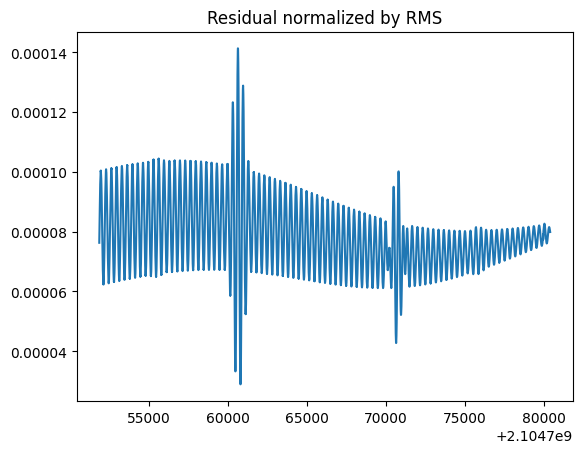

In [23]:
A = dl_sr[sl]
B = dl_sr_wdm[sl]
abs_res = np.abs(A-B)
norm = np.sqrt(np.mean(A*A))
plt.plot(times[sl], abs_res/norm)
plt.title("Residual normalized by RMS")
plt.show()

In [24]:
A = dl_sr[sl].astype(complex)
B = dl_sr_wdm[sl].astype(complex)

alpha = np.vdot(A, B) / np.vdot(A, A)   # complex scalar best fit
B_fit = alpha * A

rel_before = np.linalg.norm(A - B) / np.linalg.norm(A)
rel_after  = np.linalg.norm(B_fit - B) / np.linalg.norm(B)  # or /||A||
print("alpha:", alpha, " |alpha|:", abs(alpha), " arg(alpha):", np.angle(alpha))
print("relL2 before:", rel_before)
print("relL2 after (remove best complex scaling):", rel_after)


alpha: (0.9999987949405694+0j)  |alpha|: 0.9999987949405694  arg(alpha): 0.0
relL2 before: 7.96350692225036e-05
relL2 after (remove best complex scaling): 7.962604675938667e-05


In [25]:
A = dl_sr[sl].astype(float)
B = dl_sr_wdm[sl].astype(float)
dt = times[1]-times[0]

res = B - A
dA  = np.gradient(A, dt)
tau = tau_s[sl]   # make sure you have tau_s computed for full times

X = tau * dA
beta = - np.vdot(X, res) / np.vdot(X, X)
print("beta:", beta)

# how much of the residual is explained?
res2 = res + beta * X
print("relL2 before:", np.linalg.norm(res)/np.linalg.norm(A))
print("relL2 after :", np.linalg.norm(res2)/np.linalg.norm(A))
print("corr(res, tau*dA):", np.corrcoef(res, X)[0,1])


beta: 8.1153614698038e-05
relL2 before: 7.963506922250374e-05
relL2 after : 7.908364409122373e-05
corr(res, tau*dA): -0.7128332407503711
